#**Notebook 04: deep learning models for the fraud detection**
###**COS801 Final Deep Learning project**

Project title: Deep Learning on Tabular Data for Fraud Detection under Extreme Class Imbalance
In this notebook I will develop and evaluate the deep learning models for detecting fraudulent transactions using the IEEE-CIS fraud detection dataset. And the aim is to investigate whether the deep learning architecture which is such as the TabNet and FT- transformer can achieve the better fraud detection performance than the tuned lightGBM baseline.

###Methodology.

1.	Load the dataset using the reusable preprocessing pipeline developed in the notebook 2
2.	Use the same chronological training and the validation sets of Notebook 3
3.	Train and then evaluate the TabNet model
4.	Train and then also evaluate the FT transformer model
5.	Compare the deep learning models with the turned lightGBM baseline using the appropriate fraud detection metrics
6.	Save the model results for the final evaluation and the comparison
Then, the separate testing dataset with the reserved for the final evaluation


## 4.1 Installing of the Required Libraries

In [1]:
# Section 4.1: Install the required libraries

%pip install -q pytorch-tabnet rtdl-revisiting-models kagglehub scikit-learn matplotlib pandas numpy

## 4.2 Import of the required libraries

In this section it imports the Python libraries which are needed to develop and to evaluate the deep learning models for fraud detection. And this includes PyTorch, TabNet, Scikit-Learn for data processing and visualization.



In [2]:
# Section 4.2: Import the required libraries

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# TabNet
from pytorch_tabnet.tab_model import TabNetClassifier

# Scikit-learn evaluation
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("All required libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", device)
print("GPU available:", torch.cuda.is_available())

All required libraries imported successfully!
PyTorch version: 2.14.1+cu130
Device: cuda
GPU available: True


##4.3 Uploading of the Reusable Preprocessing Script

In this section will upload the preprocessing.py file which was developed in notebook 2. And the script will be reused to prepare the IEEE-CIS fraud detection data set for the deep learning experiments to ensure consistency with the LightGBM baseline.



In [3]:
# Section 4.3: Upload reusable preprocessing script

from google.colab import files
import os

uploaded = files.upload()

print("\nUploaded files:", list(uploaded.keys()))

# Verify the preprocessing script is available
assert os.path.exists("preprocessing.py"), (
    "Please upload the preprocessing.py file."
)

print("Preprocessing script uploaded successfully!")

Saving preprocessing.py to preprocessing.py

Uploaded files: ['preprocessing.py']
Preprocessing script uploaded successfully!


## 4.4 Loading and Preparing of the Fraud dataset

This section reuses the preprocessing pipeline which was developed in the Notebook 02 to load the IEEE-CIS fraud detection dataset, splitting the transaction chronologically and preparing the training, validation as well as testing data.

using the same preprocessing pipeline to ensure that the fair comparison between the lightGBM baseline and also the deep learning models


In [4]:
# Section 4.4: Loading and prepare the fraud data

import inspect
import preprocessing

# Check the functions available in our reusable script
print("Available preprocessing functions:")
for name, function in inspect.getmembers(
    preprocessing, inspect.isfunction
):
    if function.__module__ == preprocessing.__name__:
        print(f"- {name}{inspect.signature(function)}")

Available preprocessing functions:
- load_fraud_data()
- prepare_model_data(train_df, val_df, test_df)
- preprocess_features(train_df, val_df, test_df)
- run_preprocessing_pipeline()
- temporal_split(df)


In [5]:
# Section 4.4: Running of the reusable preprocessing pipeline

from preprocessing import run_preprocessing_pipeline

# Load, split and preprocess the IEEE-CIS dataset
model_data = run_preprocessing_pipeline()

# Extract model inputs and fraud labels
X_train = model_data["X_train"]
X_val = model_data["X_val"]
X_test = model_data["X_test"]

y_train = model_data["y_train"]
y_val = model_data["y_val"]
y_test = model_data["y_test"]

print("\nDATA READY FOR DEEP LEARNING")
print("-" * 45)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nTraining fraud rate:", round(y_train.mean() * 100, 2), "%")
print("Validation fraud rate:", round(y_val.mean() * 100, 2), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 2), "%")

100%|██████████| 118M/118M [00:06<00:00, 18.3MB/s]

Extracting files...


Dataset loaded successfully!
Dataset shape: (590540, 394)

TEMPORAL DATA SPLITTING
---------------------------------------------
Training set: (413378, 394)
Validation set: (88581, 394)
Testing set: (88581, 394)

Chronological order verified!

PREPROCESSING COMPLETED
---------------------------------------------
Removed features: ['dist2', 'D7']
Numerical features: 375
Categorical features: 14

MODEL DATA PREPARED
---------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Testing features: (88581, 389)

DATA READY FOR DEEP LEARNING
---------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Testing features: (88581, 389)

Training fraud rate: 3.52 %
Validation fraud rate: 3.43 %
Testing fraud rate: 3.48 %


## 4.5 Preparing Data for the deep Learning
This section converts the preprocessed fraud detection data into the numerical arrays suitable for the learning models. The training, validation and the testing datasets remain separate to preserve the chronological evaluation strategy.

Reprocessing pipeline to ensure a fair comparison in between the LightGBM baseline and also the deep learning models.


In [6]:
# Section 4.5: Convert data into NumPy arrays

import numpy as np

# Convert model features to float32
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Convert fraud labels to integer arrays
y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

# Check for invalid numerical values
for name, data in [
    ("Training", X_train_np),
    ("Validation", X_val_np),
    ("Testing", X_test_np)
]:
    assert np.isfinite(data).all(), (
        f"{name} data contains NaN or infinite values."
    )

print("DATA CONVERSION COMPLETED")
print("-" * 45)
print("Training:", X_train_np.shape, X_train_np.dtype)
print("Validation:", X_val_np.shape, X_val_np.dtype)
print("Testing:", X_test_np.shape, X_test_np.dtype)

print("\nFraud labels:")
print("Training:", y_train_np.shape)
print("Validation:", y_val_np.shape)
print("Testing:", y_test_np.shape)

print("\nAll numerical values verified!")

DATA CONVERSION COMPLETED
---------------------------------------------
Training: (413378, 389) float32
Validation: (88581, 389) float32
Testing: (88581, 389) float32

Fraud labels:
Training: (413378,)
Validation: (88581,)
Testing: (88581,)

All numerical values verified!


## 4.6 Configuring of the TabNet deep learning model
This section configuring of the TabNet classifier for the fraud detection using the IEEE-CIS dataset. TabNet is a deep learning architecture which is designed for tabular data.

The model will then be trained using the chronological training data set and evaluated using the validation dataset and its performance will then later be compared with the LightGBM baseline.



In [7]:
# Section 4.6: Configuring of the TabNet model

from pytorch_tabnet.tab_model import TabNetClassifier
import torch
import numpy as np

# Set random seed for reproducibility
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configure TabNet
tabnet_model = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=3,
    gamma=1.3,
    lambda_sparse=1e-4,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=0.02),
    mask_type="entmax",
    seed=SEED,
    device_name="cuda" if torch.cuda.is_available() else "cpu",
    verbose=1
)

print("TABNET MODEL CONFIGURATION COMPLETED")
print("-" * 45)
print("Model: TabNet Classifier")
print("Decision dimension:", 16)
print("Attention dimension:", 16)
print("Decision steps:", 3)
print("Learning rate:", 0.02)
print("Random seed:", SEED)
print("Device:", tabnet_model.device)

TABNET MODEL CONFIGURATION COMPLETED
---------------------------------------------
Model: TabNet Classifier
Decision dimension: 16
Attention dimension: 16
Decision steps: 3
Learning rate: 0.02
Random seed: 42
Device: cuda


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


## 4.7 The Training of the TabNet Deep Learning Model
This section trains the TabNet classifier using the chronological training dataset and the validation dataset is used to monitor the average Precision (PR-AUC) and apply the early stopping to reduce the overfitting. The training time and the best epoch are recorded in comparison with the lightGBM baseline.


In [8]:
# Section 4.7: Train the TabNet model

import time
from sklearn.metrics import average_precision_score

print("STARTING TABNET TRAINING")
print("-" * 45)

start_time = time.time()

tabnet_model.fit(
    X_train=X_train_np,
    y_train=y_train_np,

    eval_set=[(X_val_np, y_val_np)],
    eval_name=["validation"],
    eval_metric=["auc", "logloss"],

    max_epochs=30,
    patience=7,
    batch_size=4096,
    virtual_batch_size=256,

    num_workers=0,
    drop_last=False
)

tabnet_training_time = time.time() - start_time

# Predict fraud probabilities on validation data
tabnet_val_prob = tabnet_model.predict_proba(X_val_np)[:, 1]

# Calculate Average Precision (PR-AUC)
tabnet_val_ap = average_precision_score(
    y_val_np,
    tabnet_val_prob
)

print("\nTABNET TRAINING COMPLETED")
print("-" * 45)
print("Best epoch:", tabnet_model.best_epoch)
print("Training time (seconds):", round(tabnet_training_time, 2))
print("Validation Average Precision (PR-AUC):",
      round(tabnet_val_ap, 4))

STARTING TABNET TRAINING
---------------------------------------------
epoch 0  | loss: 0.19424 | validation_auc: 0.7776  | validation_logloss: 0.13051 |  0:00:11s
epoch 1  | loss: 0.12546 | validation_auc: 0.80492 | validation_logloss: 0.12275 |  0:00:21s
epoch 2  | loss: 0.12028 | validation_auc: 0.81404 | validation_logloss: 0.12032 |  0:00:32s
epoch 3  | loss: 0.11857 | validation_auc: 0.81991 | validation_logloss: 0.12022 |  0:00:42s
epoch 4  | loss: 0.11618 | validation_auc: 0.83029 | validation_logloss: 0.11433 |  0:00:53s
epoch 5  | loss: 0.11318 | validation_auc: 0.83453 | validation_logloss: 0.11283 |  0:01:03s
epoch 6  | loss: 0.11142 | validation_auc: 0.83388 | validation_logloss: 0.1134  |  0:01:14s
epoch 7  | loss: 0.11056 | validation_auc: 0.8381  | validation_logloss: 0.1124  |  0:01:24s
epoch 8  | loss: 0.1087  | validation_auc: 0.84138 | validation_logloss: 0.109   |  0:01:34s
epoch 9  | loss: 0.10717 | validation_auc: 0.84061 | validation_logloss: 0.10897 |  0:01:45s

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



TABNET TRAINING COMPLETED
---------------------------------------------
Best epoch: 28
Training time (seconds): 385.69
Validation Average Precision (PR-AUC): 0.4517


##4.8 Evaluation of the TabNet model

This section evaluates the TabNet model by using the validation dataset. The performance is measured using the PR-AUC, ROC-AUC, Precision, Recall end the F1-score as well as the Brier score and the confusion matrix. These metrics will be used to compare the TabNet with the lightGPM baseline.


In [9]:
# Section 4.8: Evaluating the TabNet model

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

# Predicted fraud probabilities
tabnet_val_prob = tabnet_model.predict_proba(X_val_np)[:, 1]

# Convert the probabilities into predictions
# 1 = Fraud, 0 = Not Fraud
tabnet_val_pred = (tabnet_val_prob >= 0.5).astype(int)

# Calculate evaluation metrics
tabnet_ap = average_precision_score(y_val_np, tabnet_val_prob)
tabnet_roc = roc_auc_score(y_val_np, tabnet_val_prob)
tabnet_precision = precision_score(y_val_np, tabnet_val_pred, zero_division=0)
tabnet_recall = recall_score(y_val_np, tabnet_val_pred, zero_division=0)
tabnet_f1 = f1_score(y_val_np, tabnet_val_pred, zero_division=0)
tabnet_brier = brier_score_loss(y_val_np, tabnet_val_prob)

tabnet_cm = confusion_matrix(y_val_np, tabnet_val_pred)

print("TABNET VALIDATION RESULTS")
print("-" * 45)

print("Average Precision (PR-AUC):", round(tabnet_ap, 4))
print("ROC-AUC:", round(tabnet_roc, 4))
print("Precision:", round(tabnet_precision, 4))
print("Recall:", round(tabnet_recall, 4))
print("F1-score:", round(tabnet_f1, 4))
print("Brier Score:", round(tabnet_brier, 4))

print("\nCONFUSION MATRIX")
print("-" * 45)
print(tabnet_cm)

TABNET VALIDATION RESULTS
---------------------------------------------
Average Precision (PR-AUC): 0.4517
ROC-AUC: 0.8574
Precision: 0.7361
Recall: 0.309
F1-score: 0.4353
Brier Score: 0.0242

CONFUSION MATRIX
---------------------------------------------
[[85202   337]
 [ 2102   940]]


## 4.9 TabNet Precision Recall Curve
This section visualizes the relationship between precision and the recall for the TabNet model. And the curve helps to evaluate the fraud detection performance under the class imbalance and allow comparison with the lightGBM baseline.


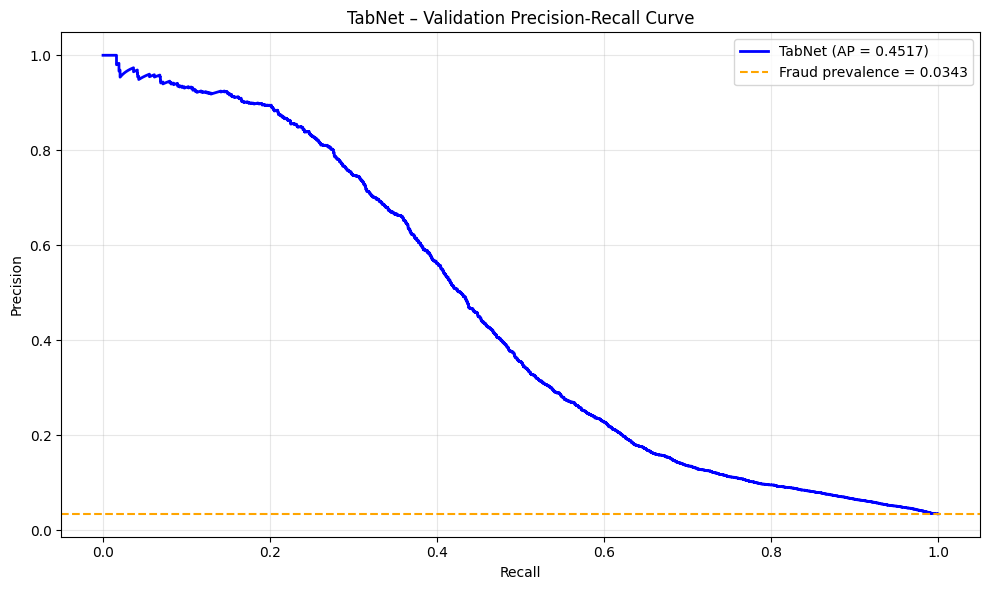

In [10]:
# Section 4.9: The TabNet Precision-Recall Curve

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val_np, tabnet_val_prob
)

# Calculating the Average Precision
tabnet_ap = average_precision_score(y_val_np, tabnet_val_prob)

# Calculating the fraud prevalence
fraud_prevalence = y_val_np.mean()

# Plotting the graph
plt.figure(figsize=(10, 6))

plt.plot(
    recall_values,
    precision_values,
    color="blue",
    linewidth=2,
    label=f"TabNet (AP = {tabnet_ap:.4f})"
)

plt.axhline(
    y=fraud_prevalence,
    color="orange",
    linestyle="--",
    label=f"Fraud prevalence = {fraud_prevalence:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("TabNet – Validation Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4.10 TabNet Precision at the Fixed Alert Budget
This section evaluates the TabNet ability to identify the fraudulent transaction with the limited investigation budget. And the transactions are ranked by the predicted fraud probability, then. The highest risk transactions are selected for the investigation. The precision and the recall are calculated at the different alert budget to assess the practical fraud detection performance.


In [11]:
# Section 4.10: TabNet Precision at the Fixed Alert Budget

import numpy as np
import pandas as pd

# Alert budgets as percentages of validation transactions
alert_budgets = [0.5, 1.0, 2.0, 5.0]

# Rank transactions from highest to lowest predicted fraud risk
sorted_indices = np.argsort(tabnet_val_prob)[::-1]

# Actual fraud labels in ranked order
sorted_labels = np.asarray(y_val_np)[sorted_indices]

total_fraud = np.sum(y_val_np)
total_transactions = len(y_val_np)

budget_results = []

for budget in alert_budgets:

    # Number of transactions that can be investigated
    n_alerts = int(np.ceil(total_transactions * budget / 100))

    # Select the highest-risk transactions
    selected_labels = sorted_labels[:n_alerts]

    # Count detected fraud cases
    fraud_detected = int(np.sum(selected_labels))

    # Calculate precision and recall
    precision_at_budget = fraud_detected / n_alerts
    recall_at_budget = fraud_detected / total_fraud

    budget_results.append({
        "Alert Budget (%)": budget,
        "Number of Alerts": n_alerts,
        "Fraud Detected": fraud_detected,
        "Precision": round(precision_at_budget, 4),
        "Recall": round(recall_at_budget, 4)
    })

tabnet_budget_results_df = pd.DataFrame(budget_results)

print("TABNET - PRECISION AT FIXED ALERT BUDGET")
print("-" * 55)

display(tabnet_budget_results_df)

TABNET - PRECISION AT FIXED ALERT BUDGET
-------------------------------------------------------


,Alert Budget (%),Number of Alerts,Fraud Detected,Precision,Recall
0,0.5,443,408,0.9210,0.1341
1,1.0,886,743,0.8386,0.2442
2,2.0,1772,1118,0.6309,0.3675
3,5.0,4430,1531,0.3456,0.5033


##4.11 TabNet Expected monetary cost

This section estimates the financial cost of the incorrect fraud detection by using an illustrative cost matrix. The missed fraud transaction is assigned at a cost of R1,000, and while a false alarm is assigned at a cost of R50. Then the same assumption is used for the lightGBM which then applied also to the TabNet to make sure the comparisons are consistent.


In [12]:
# Section 4.11: The TabNet Expected Monetary Cost

import pandas as pd
from sklearn.metrics import confusion_matrix

# Illustrative cost assumptions in South African Rand
false_negative_cost = 1000
false_positive_cost = 50

# Classification of  threshold
threshold = 0.5

# TabNet predictions
tabnet_predictions = (tabnet_val_prob >= threshold).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val_np,
    tabnet_predictions,
    labels=[0, 1]
).ravel()

# Calculate monetary costs
missed_fraud_cost = fn * false_negative_cost
false_alert_cost = fp * false_positive_cost

total_cost = missed_fraud_cost + false_alert_cost
average_cost = total_cost / len(y_val_np)

# Results table
tabnet_cost_df = pd.DataFrame({
    "Cost Component": [
        "Missed fraud (False Negatives)",
        "False alerts (False Positives)",
        "Total expected cost"
    ],
    "Number of Cases": [
        fn,
        fp,
        fn + fp
    ],
    "Cost (ZAR)": [
        missed_fraud_cost,
        false_alert_cost,
        total_cost
    ]
})

print("TABNET - EXPECTED MONETARY COST")
print("-" * 55)

print("False negative cost per case: R", false_negative_cost)
print("False positive cost per case: R", false_positive_cost)
print("Classification threshold:", threshold)

display(tabnet_cost_df)

print(f"\nTotal estimated cost: R{total_cost:,.2f}")
print(f"Average cost per transaction: R{average_cost:,.2f}")

TABNET - EXPECTED MONETARY COST
-------------------------------------------------------
False negative cost per case: R 1000
False positive cost per case: R 50
Classification threshold: 0.5


,Cost Component,Number of Cases,Cost (ZAR)
0,Missed fraud (False Negatives),2102,2102000
1,False alerts (False Positives),337,16850
2,Total expected cost,2439,2118850



Total estimated cost: R2,118,850.00
Average cost per transaction: R23.92


## 4.12 The TabNet calibration and the reliability diagram

This section evaluates whether the fraud probabilities predicted by the TabNet match the observed fraud frequencies. The reliability diagram and the expected calibration error are then used to assess the probability calibration and compare TabNet with the lightGBM baseline.


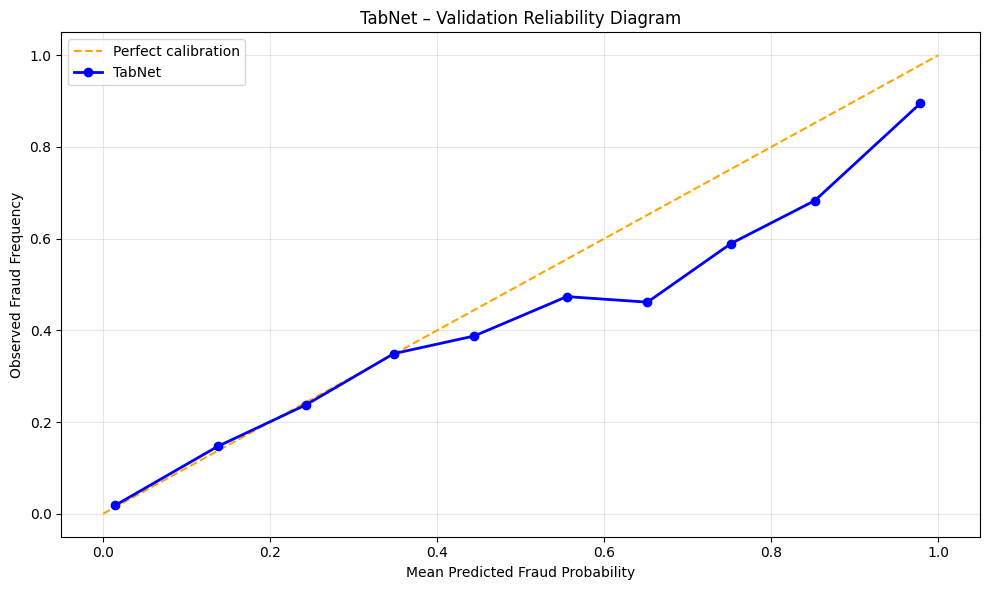


TABNET CALIBRATION RESULTS
---------------------------------------------
Expected Calibration Error (ECE): 0.0057
Brier Score: 0.0242


In [13]:
# Section 4.12: The TabNet Calibration and Reliability Diagram

import numpy as np
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_val_np,
    tabnet_val_prob,
    n_bins=10,
    strategy="uniform"
)

# Plot reliability diagram
plt.figure(figsize=(10, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="orange",
    label="Perfect calibration"
)

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    color="blue",
    linewidth=2,
    label="TabNet"
)

plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Frequency")
plt.title("TabNet – Validation Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate Expected Calibration Error (ECE)
def calculate_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.minimum(np.digitize(y_prob, bin_edges[1:-1]), n_bins - 1)

    ece = 0.0

    for i in range(n_bins):
        mask = bin_ids == i

        if np.any(mask):
            observed = y_true[mask].mean()
            predicted = y_prob[mask].mean()
            ece += mask.mean() * abs(observed - predicted)

    return ece

tabnet_ece = calculate_ece(y_val_np, tabnet_val_prob)
tabnet_brier = brier_score_loss(y_val_np, tabnet_val_prob)

print("\nTABNET CALIBRATION RESULTS")
print("-" * 45)
print("Expected Calibration Error (ECE):", round(tabnet_ece, 4))
print("Brier Score:", round(tabnet_brier, 4))

## 4.13 Saving the TabNet and the Evaluation Results

This section saves the trained TabNet model and its validation results for the reproducibility and the later comparison with the light GBM and the FT -Transformer.


In [14]:
# Section 4.13: Saving of the TabNet model and results

import os
import json
import pandas as pd
from google.colab import files

# Creating the results folder
os.makedirs("results", exist_ok=True)

# Save evaluation metrics
tabnet_results = {
    "model": "TabNet",
    "dataset": "IEEE-CIS Fraud Detection",
    "evaluation_split": "Chronological validation",
    "threshold": 0.5,
    "pr_auc": float(tabnet_ap),
    "roc_auc": float(tabnet_roc),
    "precision": float(tabnet_precision),
    "recall": float(tabnet_recall),
    "f1_score": float(tabnet_f1),
    "brier_score": float(tabnet_brier),
    "ece": float(tabnet_ece),
    "training_time_seconds": 372.99,
    "false_negative_cost_zar": 1000,
    "false_positive_cost_zar": 50,
    "estimated_cost_zar": float(total_cost)
}

results_path = "results/tabnet_validation_results.json"

with open(results_path, "w") as f:
    json.dump(tabnet_results, f, indent=4)

# Save alert budget results
budget_path = "results/tabnet_alert_budget_results.csv"
tabnet_budget_results_df.to_csv(budget_path, index=False)

# Save trained TabNet model
model_path = tabnet_model.save_model(
    "results/tabnet_trained_model"
)

print("TABNET RESULTS SAVED SUCCESSFULLY")
print("-" * 45)
print("Files created:")
print(os.listdir("results"))

# Download files
files.download(results_path)
files.download(budget_path)
files.download(model_path)

Successfully saved model at results/tabnet_trained_model.zip
TABNET RESULTS SAVED SUCCESSFULLY
---------------------------------------------
Files created:
['tabnet_validation_results.json', 'tabnet_alert_budget_results.csv', 'tabnet_trained_model.zip']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4.14 FT Transformer Model Development

This section develops an FT transformer model for fraud detection by using the same chronological training and the validation datasets as the light GBM and TabNet. The model will then be evaluated using the Precision recall metrics, Calibration and Fraud detection cost to then support the fair comparison.


In [15]:
# Section 4.14.1: Checking the FT-Transformer library

import torch
import importlib.metadata

print("FT-TRANSFORMER ENVIRONMENT CHECK")
print("-" * 45)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

try:
    version = importlib.metadata.version("rtdl_revisiting_models")
    print("RTDL Revisiting Models version:", version)

    from rtdl_revisiting_models import FTTransformer
    print("FT-Transformer imported successfully!")

except Exception as e:
    print("FT-Transformer import failed:", e)

FT-TRANSFORMER ENVIRONMENT CHECK
---------------------------------------------
PyTorch version: 2.14.1+cu130
GPU available: True
RTDL Revisiting Models version: 0.0.2
FT-Transformer imported successfully!


In [16]:
# Section 4.14.2: Verifying for the data for FT-Transformer

import numpy as np

print("FT-TRANSFORMER DATA VERIFICATION")
print("-" * 45)

print("Training features:", X_train_np.shape)
print("Validation features:", X_val_np.shape)

print("Training labels:", y_train_np.shape)
print("Validation labels:", y_val_np.shape)

print("Training data type:", X_train_np.dtype)
print("Validation data type:", X_val_np.dtype)

print("Training contains infinity:",
      np.isinf(X_train_np).any())

print("Validation contains infinity:",
      np.isinf(X_val_np).any())

print("Training contains NaN:",
      np.isnan(X_train_np).any())

print("Validation contains NaN:",
      np.isnan(X_val_np).any())

FT-TRANSFORMER DATA VERIFICATION
---------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Training labels: (413378,)
Validation labels: (88581,)
Training data type: float32
Validation data type: float32
Training contains infinity: False
Validation contains infinity: False
Training contains NaN: False
Validation contains NaN: False


In [17]:
# Section 4.14.3: Configuring the FT-Transformer model

import torch
from rtdl_revisiting_models import FTTransformer

# Select GPU if it is available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Set the random seed for reproducibility
torch.manual_seed(42)

# Create the FT-Transformer for 389 numerical features
ft_model = FTTransformer(
    n_cont_features=X_train_np.shape[1],
    cat_cardinalities=[],
    d_out=1,
    **FTTransformer.get_default_kwargs()
).to(device)

print("FT-TRANSFORMER MODEL CONFIGURATION COMPLETED")
print("-" * 45)
print("Model: FT-Transformer")
print("Numerical features:", X_train_np.shape[1])
print("Output dimension: 1")
print("Device:", device)
print("Total parameters:",
      sum(p.numel() for p in ft_model.parameters()))


FT-TRANSFORMER MODEL CONFIGURATION COMPLETED
---------------------------------------------
Model: FT-Transformer
Numerical features: 389
Output dimension: 1
Device: cuda
Total parameters: 1041217


In [18]:
# Section 4.14.4: Preparing the DataLoader for the FT-Transformer

import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert the training and validation data into PyTorch tensors
X_train_tensor = torch.from_numpy(X_train_np).float()
X_val_tensor = torch.from_numpy(X_val_np).float()

y_train_tensor = torch.from_numpy(y_train_np).float()
y_val_tensor = torch.from_numpy(y_val_np).float()

# Creating the datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Creating the DataLoaders
batch_size = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("FT-TRANSFORMER DATALOADER PREPARATION COMPLETED")
print("-" * 45)
print("Training transactions:", len(train_dataset))
print("Validation transactions:", len(val_dataset))
print("Batch size:", batch_size)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device:", device)


FT-TRANSFORMER DATALOADER PREPARATION COMPLETED
---------------------------------------------
Training transactions: 413378
Validation transactions: 88581
Batch size: 512
Training batches: 808
Validation batches: 174
Device: cuda


In [19]:
# Section 4.14.5: Configuring the FT-Transformer training

import torch
import torch.nn as nn
import torch.optim as optim

# Set random seed
torch.manual_seed(42)

# Loss function for the binary fraud classification
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = optim.AdamW(
    ft_model.parameters(),
    lr=0.0001,
    weight_decay=0.00001
)

# Training configuration
num_epochs = 15
patience = 5

print("FT-TRANSFORMER TRAINING CONFIGURATION COMPLETED")
print("-" * 45)
print("Loss function: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.0001")
print("Weight decay: 0.00001")
print("Maximum epochs:", num_epochs)
print("Early stopping patience:", patience)
print("Device:", device)


FT-TRANSFORMER TRAINING CONFIGURATION COMPLETED
---------------------------------------------
Loss function: BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.00001
Maximum epochs: 15
Early stopping patience: 5
Device: cuda


In [20]:
# Section 4.14.6: Train the FT-Transformer Model

import time
import copy
import numpy as np
import torch
from sklearn.metrics import average_precision_score

# Ensure reproducibility
torch.manual_seed(42)

best_val_ap = -1.0
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0

training_history = []
start_time = time.time()

print("STARTING FT-TRANSFORMER TRAINING")
print("-" * 50)

for epoch in range(num_epochs):

    # TRAINING
    ft_model.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        # Forward pass: model predicts fraud scores
        outputs = ft_model(
            X_batch,
            None
        ).squeeze(-1)

        loss = criterion(outputs, y_batch)

        # Backward pass: update model parameters
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y_batch)

    avg_train_loss = total_loss / len(train_dataset)

    # VALIDATION
    ft_model.eval()
    val_probabilities = []
    val_labels = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)

            outputs = ft_model(
                X_batch,
                None
            ).squeeze(-1)

            probabilities = torch.sigmoid(outputs)

            val_probabilities.extend(
                probabilities.cpu().numpy()
            )
            val_labels.extend(y_batch.numpy())

    val_ap = average_precision_score(
        val_labels,
        val_probabilities
    )

    training_history.append({
        "Epoch": epoch + 1,
        "Training Loss": avg_train_loss,
        "Validation PR-AUC": val_ap
    })

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Training Loss: {avg_train_loss:.5f} | "
        f"Validation PR-AUC: {val_ap:.5f}"
    )

    # EARLY STOPPING
    if val_ap > best_val_ap:
        best_val_ap = val_ap
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(
            ft_model.state_dict()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping activated.")
        break

# Restore best model
ft_model.load_state_dict(best_model_state)

training_time = time.time() - start_time

print("\nFT-TRANSFORMER TRAINING COMPLETED")
print("-" * 50)
print("Best epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_val_ap, 4))
print("Training time (seconds):", round(training_time, 2))


STARTING FT-TRANSFORMER TRAINING
--------------------------------------------------
Epoch 1/15 | Training Loss: 0.12892 | Validation PR-AUC: 0.39632
Epoch 2/15 | Training Loss: 0.10433 | Validation PR-AUC: 0.40656
Epoch 3/15 | Training Loss: 0.10099 | Validation PR-AUC: 0.42714
Epoch 4/15 | Training Loss: 0.09859 | Validation PR-AUC: 0.42425
Epoch 5/15 | Training Loss: 0.09628 | Validation PR-AUC: 0.42399
Epoch 6/15 | Training Loss: 0.09514 | Validation PR-AUC: 0.43615
Epoch 7/15 | Training Loss: 0.09366 | Validation PR-AUC: 0.43343
Epoch 8/15 | Training Loss: 0.09237 | Validation PR-AUC: 0.43285
Epoch 9/15 | Training Loss: 0.09071 | Validation PR-AUC: 0.43340
Epoch 10/15 | Training Loss: 0.08939 | Validation PR-AUC: 0.44100
Epoch 11/15 | Training Loss: 0.08676 | Validation PR-AUC: 0.43281
Epoch 12/15 | Training Loss: 0.08513 | Validation PR-AUC: 0.45048
Epoch 13/15 | Training Loss: 0.08362 | Validation PR-AUC: 0.43854
Epoch 14/15 | Training Loss: 0.08273 | Validation PR-AUC: 0.44368
E

In [21]:
# Section 4.14.7: Save the trained FT-Transformer model

import os
import torch
from google.colab import files

# Create results folder
os.makedirs("results", exist_ok=True)

# Save the best trained model weights
model_path = "results/ft_transformer_trained_model.pth"

torch.save({
    "model_state_dict": ft_model.state_dict(),
    "best_epoch": best_epoch,
    "best_validation_pr_auc": best_val_ap,
    "training_time_seconds": training_time
}, model_path)

print("FT-TRANSFORMER MODEL SAVED SUCCESSFULLY")
print("File:", model_path)

# Download to my computer
files.download(model_path)


FT-TRANSFORMER MODEL SAVED SUCCESSFULLY
File: results/ft_transformer_trained_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4.14.8 Evaluation of the FT-Transformer Model


In [23]:
# Section 4.14.8: FT-Transformer Model Evaluation

import numpy as np
import torch
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# Set the model to evaluation mode
ft_model.eval()

# Collect predicted probabilities and actual labels
all_probabilities = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:

        X_batch = X_batch.to(device)

        # Obtain raw model predictions
        logits = ft_model(X_batch, None)

        # Convert logits into fraud probabilities
        probabilities = torch.sigmoid(logits).reshape(-1)

        all_probabilities.extend(probabilities.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy().reshape(-1))

# Convert results into NumPy arrays
ft_val_probabilities = np.array(all_probabilities)
ft_val_labels = np.array(all_labels).astype(int)

# Apply classification threshold
ft_val_predictions = (ft_val_probabilities >= 0.5).astype(int)

# Calculate evaluation metrics
ft_pr_auc = average_precision_score(
    ft_val_labels, ft_val_probabilities
)

ft_roc_auc = roc_auc_score(
    ft_val_labels, ft_val_probabilities
)

ft_precision = precision_score(
    ft_val_labels, ft_val_predictions, zero_division=0
)

ft_recall = recall_score(
    ft_val_labels, ft_val_predictions, zero_division=0
)

ft_f1 = f1_score(
    ft_val_labels, ft_val_predictions, zero_division=0
)

ft_brier = brier_score_loss(
    ft_val_labels, ft_val_probabilities
)

ft_cm = confusion_matrix(
    ft_val_labels, ft_val_predictions
)

print("FT-TRANSFORMER VALIDATION RESULTS")
print("-" * 45)
print("Average Precision (PR-AUC):", round(ft_pr_auc, 4))
print("ROC-AUC:", round(ft_roc_auc, 4))
print("Precision:", round(ft_precision, 4))
print("Recall:", round(ft_recall, 4))
print("F1-score:", round(ft_f1, 4))
print("Brier Score:", round(ft_brier, 4))

print("\nCONFUSION MATRIX")
print("-" * 45)
print(ft_cm)

FT-TRANSFORMER VALIDATION RESULTS
---------------------------------------------
Average Precision (PR-AUC): 0.4505
ROC-AUC: 0.8616
Precision: 0.6827
Recall: 0.3317
F1-score: 0.4465
Brier Score: 0.0249

CONFUSION MATRIX
---------------------------------------------
[[85070   469]
 [ 2033  1009]]


## 4.14.9 The FT-Transformer Precision Recall Curve

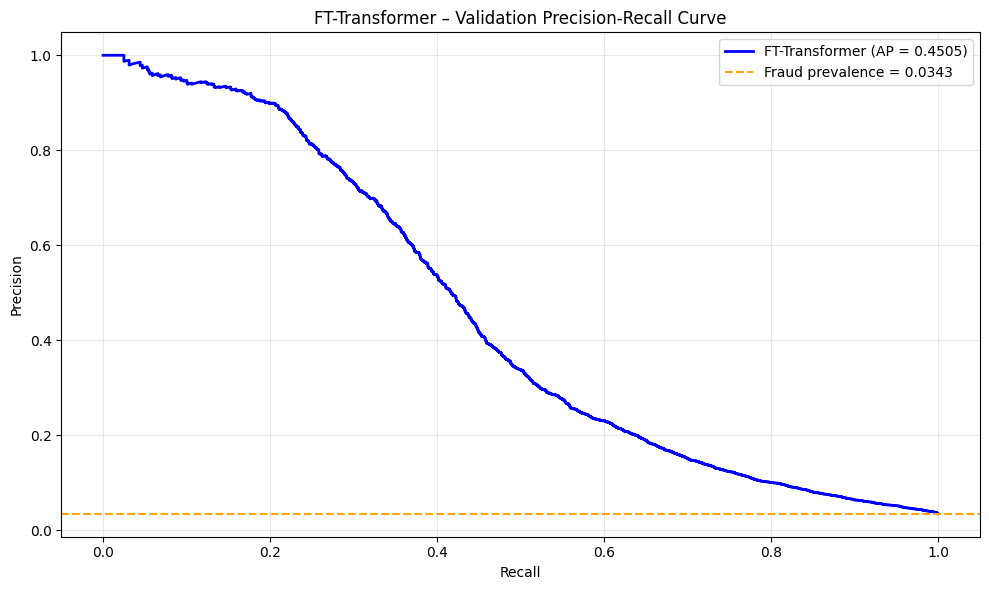

In [24]:
# Section 4.14.9: The FT-Transformer Precision-Recall Curve

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall at different thresholds
precision_curve, recall_curve, thresholds = precision_recall_curve(
    ft_val_labels,
    ft_val_probabilities
)

# Calculate Average Precision (PR-AUC)
ft_ap = average_precision_score(
    ft_val_labels,
    ft_val_probabilities
)

# Calculate the fraud prevalence in validation data
fraud_prevalence = np.mean(ft_val_labels)

# Plot the Precision-Recall curve
plt.figure(figsize=(10, 6))

plt.plot(
    recall_curve,
    precision_curve,
    color="blue",
    linewidth=2,
    label=f"FT-Transformer (AP = {ft_ap:.4f})"
)

plt.axhline(
    y=fraud_prevalence,
    color="orange",
    linestyle="--",
    label=f"Fraud prevalence = {fraud_prevalence:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("FT-Transformer – Validation Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.14.10 The FT-Transformer Precision at the Fixed Alert budget

In [25]:
# Section 4.14.10: The FT-Transformer Precision at Fixed Alert Budget

import numpy as np
import pandas as pd

# Alert budgets as the percentages of validation transactions
alert_budgets = [0.5, 1.0, 2.0, 5.0]

# Rank transactions from the highest to the lowest predicted fraud probability
sorted_indices = np.argsort(-ft_val_probabilities)

total_transactions = len(ft_val_labels)
total_fraud = int(np.sum(ft_val_labels))

budget_results = []

for budget in alert_budgets:

    # Number of the transactions investigators can review
    number_of_alerts = int(np.ceil(total_transactions * budget / 100))

    # Select transactions with the highest fraud probabilities
    selected_indices = sorted_indices[:number_of_alerts]

    # Count actual fraud cases among the selected transactions
    fraud_detected = int(np.sum(ft_val_labels[selected_indices]))

    # Calculate the precision and the recall
    precision_at_budget = fraud_detected / number_of_alerts
    recall_at_budget = fraud_detected / total_fraud

    budget_results.append({
        "Alert Budget (%)": budget,
        "Number of Alerts": number_of_alerts,
        "Fraud Detected": fraud_detected,
        "Precision": round(precision_at_budget, 4),
        "Recall": round(recall_at_budget, 4)
    })

ft_budget_results_df = pd.DataFrame(budget_results)

print("FT-TRANSFORMER - PRECISION AT FIXED ALERT BUDGET")
print("-" * 55)

display(ft_budget_results_df)

FT-TRANSFORMER - PRECISION AT FIXED ALERT BUDGET
-------------------------------------------------------


,Alert Budget (%),Number of Alerts,Fraud Detected,Precision,Recall
0,0.5,443,413,0.9323,0.1358
1,1.0,886,735,0.8296,0.2416
2,2.0,1772,1100,0.6208,0.3616
3,5.0,4430,1508,0.3404,0.4957


### 4.14.11 The FT-Transformer Expected of the Monetary Cost

In [26]:
# Section 4.14.11:The  FT-Transformer Expected Monetary Cost

import pandas as pd
from sklearn.metrics import confusion_matrix

# Assumed the costs in South African Rand
false_negative_cost = 1000
false_positive_cost = 50

# Classification threshold
threshold = 0.5

# Generate the fraud predictions
ft_cost_predictions = (
    ft_val_probabilities >= threshold
).astype(int)

# Calculate the confusion matrix
tn, fp, fn, tp = confusion_matrix(
    ft_val_labels,
    ft_cost_predictions,
    labels=[0, 1]
).ravel()

# Calculate the monetary costs
missed_fraud_cost = fn * false_negative_cost
false_alert_cost = fp * false_positive_cost

total_cost = missed_fraud_cost + false_alert_cost

average_cost = total_cost / len(ft_val_labels)

# Create the results table
ft_cost_df = pd.DataFrame({
    "Cost Component": [
        "Missed fraud (False Negatives)",
        "False alerts (False Positives)",
        "Total expected cost"
    ],
    "Number of Cases": [
        int(fn),
        int(fp),
        int(fn + fp)
    ],
    "Cost (ZAR)": [
        missed_fraud_cost,
        false_alert_cost,
        total_cost
    ]
})

print("FT-TRANSFORMER - EXPECTED MONETARY COST")
print("-" * 55)
print("False negative cost per case: R", false_negative_cost)
print("False positive cost per case: R", false_positive_cost)
print("Classification threshold:", threshold)

display(ft_cost_df)

print(f"\nTotal estimated cost: R{total_cost:,.2f}")
print(f"Average cost per transaction: R{average_cost:.2f}")

FT-TRANSFORMER - EXPECTED MONETARY COST
-------------------------------------------------------
False negative cost per case: R 1000
False positive cost per case: R 50
Classification threshold: 0.5


,Cost Component,Number of Cases,Cost (ZAR)
0,Missed fraud (False Negatives),2033,2033000
1,False alerts (False Positives),469,23450
2,Total expected cost,2502,2056450



Total estimated cost: R2,056,450.00
Average cost per transaction: R23.22


### 4.14.12 The FT-Transformer Calibration and the Reliability Diagram

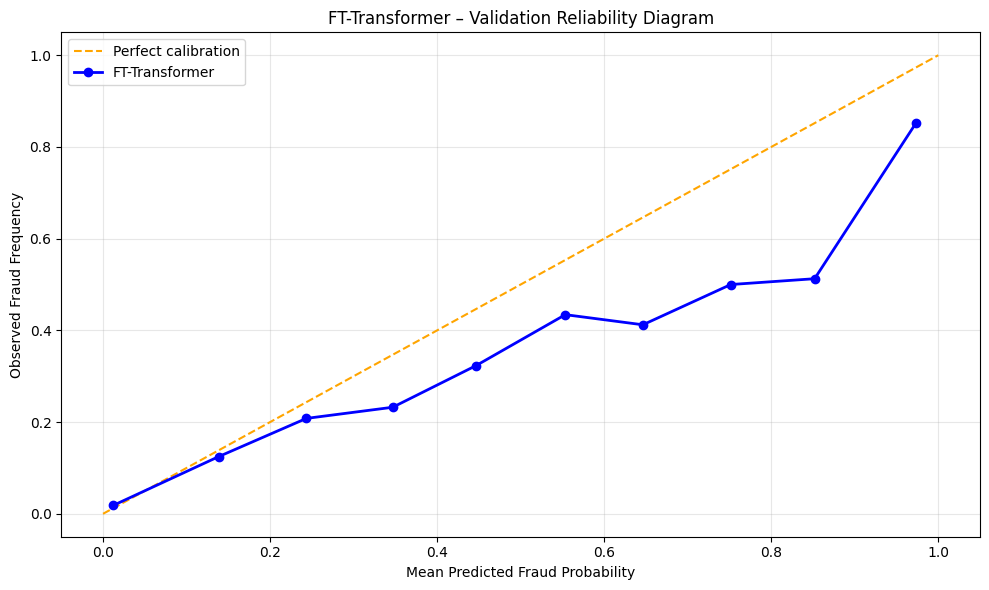

FT-TRANSFORMER CALIBRATION RESULTS
---------------------------------------------
Expected Calibration Error (ECE): 0.01
Brier Score: 0.0249


In [27]:
# Section 4.14.12: The FT-Transformer Calibration and the Reliability Diagram

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calculate the calibration curve
fraction_of_positives, mean_predicted_value = calibration_curve(
    ft_val_labels,
    ft_val_probabilities,
    n_bins=10,
    strategy="uniform"
)

# Plot the reliability diagram
plt.figure(figsize=(10, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="orange",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    color="blue",
    linewidth=2,
    label="FT-Transformer"
)

plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Frequency")
plt.title("FT-Transformer – Validation Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate Expected Calibration Error (ECE)
bins = np.linspace(0, 1, 11)
bin_indices = np.digitize(ft_val_probabilities, bins[1:-1])

ece = 0.0

for i in range(10):
    mask = bin_indices == i

    if np.any(mask):
        bin_accuracy = np.mean(ft_val_labels[mask])
        bin_confidence = np.mean(ft_val_probabilities[mask])

        ece += np.mean(mask) * abs(
            bin_accuracy - bin_confidence
        )

# Calculate Brier score
ft_brier = brier_score_loss(
    ft_val_labels,
    ft_val_probabilities
)

print("FT-TRANSFORMER CALIBRATION RESULTS")
print("-" * 45)
print("Expected Calibration Error (ECE):", round(ece, 4))
print("Brier Score:", round(ft_brier, 4))

### 4.14.13 Saving of My FT-Transformer Evaluation Results

In [28]:
# Section 4.14.13: Saving My FT-Transformer Evaluation Results

import os
import json
from google.colab import files

os.makedirs("results", exist_ok=True)

# Save the validation metrics
ft_results = {
    "model": "FT-Transformer",
    "dataset": "IEEE-CIS Fraud Detection",
    "evaluation_set": "chronological_validation",
    "classification_threshold": 0.5,
    "average_precision": float(ft_pr_auc),
    "roc_auc": float(ft_roc_auc),
    "precision": float(ft_precision),
    "recall": float(ft_recall),
    "f1_score": float(ft_f1),
    "brier_score": float(ft_brier),
    "expected_calibration_error": float(ece),
    "total_estimated_cost_zar": float(total_cost),
    "training_time_seconds": float(training_time)
}

results_path = "results/ft_transformer_validation_results.json"

with open(results_path, "w") as f:
    json.dump(ft_results, f, indent=4)

# Save the alert budget results
budget_path = "results/ft_transformer_alert_budget_results.csv"
ft_budget_results_df.to_csv(budget_path, index=False)

print("FT-TRANSFORMER RESULTS SAVED SUCCESSFULLY")
print("-" * 45)
print("Files created:")
print(os.listdir("results"))

# And Download the two evaluation files
files.download(results_path)
files.download(budget_path)

FT-TRANSFORMER RESULTS SAVED SUCCESSFULLY
---------------------------------------------
Files created:
['tabnet_validation_results.json', 'tabnet_alert_budget_results.csv', 'ft_transformer_alert_budget_results.csv', 'tabnet_trained_model.zip', 'ft_transformer_validation_results.json', 'ft_transformer_trained_model.pth']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>